# Question 2 AHHH

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [3]:
# some defaults for models
LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 30

In [4]:
def optimizer(params):
  return torch.optim.Adam(params, lr=LEARNING_RATE)

In [5]:
def mse_loss(y_hat, y, mask):
    # squared error averaged over pixels -> one number per (video, frame)
    se = ((y_hat - y) ** 2).mean(dim=(2, 3, 4))          # (B,5)

    #average over each video's available frames only
    #mask -> zeros out padded frames
    per_video = (se * mask).sum(dim=1) / mask.sum(dim=1)  # (B,)

    # average over videos: every video counts equally
    return per_video.mean()

### Setup

In [6]:
def rotate(data, rotations=1):
  # Apply requested number of 90-degree rotations (k = 0, 1, 2, 3, 4)
  if rotations % 4 != 0:
    data = torch.rot90(data, k=rotations % 4, dims=[-2, -1])
  return data

In [7]:
def mirror(data, mirror=1):
  # Apply horizontal mirroring efficiently:
  # Flipping an even number of times does nothing. An odd number of times is equal to a single flip.
  if mirror % 2 != 0:
    data = torch.flip(data, dims=[-1])
  return data

In [8]:
def speed_up(data, stride = 1):
  data = data[::stride]
  return data

In [9]:
def transform_data(data, stride=1, rotations=0, mirror_num=0):
  # Convert the video sequence to float32 and normalize
  data = data.float() / 255.0
  # Speed up / stride
  data = speed_up(data, stride)
  #mirror
  data = mirror(data, mirror_num)
  #rotate
  data = rotate(data, rotations)

  return data

In [10]:
# lets load the data shall we?
data = torchvision.datasets.MovingMNIST(root='./data',
                                        download=True,
                                        split=None,
                                        transform=lambda x: transform_data(x, stride=1)
                                        )
data

100%|██████████| 819M/819M [00:19<00:00, 41.2MB/s]


Dataset MovingMNIST
    Number of datapoints: 10000
    Root location: ./data
    StandardTransform
Transform: <function <lambda> at 0x7e9011a5efc0>

In [11]:
import torch
from torch.utils.data import Subset

# Define your split sizes or specific indices
total_size = len(data)
train_size = 8000
val_size = 1000

# Generate indices
indices = torch.randperm(total_size).tolist()

train_indices = indices[:train_size]
val_indices = indices[train_size:train_size + val_size]
test_indices = indices[train_size + val_size:]

# Create Subsets
train_dataset = Subset(data, train_indices)
val_dataset = Subset(data, val_indices)
test_dataset = Subset(data, test_indices)

print(f"Train size: {len(train_dataset)}")
print(f"Validation size: {len(val_dataset)}")
print(f"Test size: {len(test_dataset)}")

Train size: 8000
Validation size: 1000
Test size: 1000


In [12]:
train_dataset.dataset.data[0][0]

tensor([[[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]]], dtype=torch.uint8)

In [13]:
# Let's check the shape of the underlying data
print("Underlying raw data shape:", data.data.shape)

# Let's inspect a single sequence from the dataset
first_sequence = data[0]
print("Single dataset item shape/length:", first_sequence.shape if torch.is_tensor(first_sequence) else len(first_sequence))

Underlying raw data shape: torch.Size([10000, 20, 1, 64, 64])
Single dataset item shape/length: torch.Size([20, 1, 64, 64])


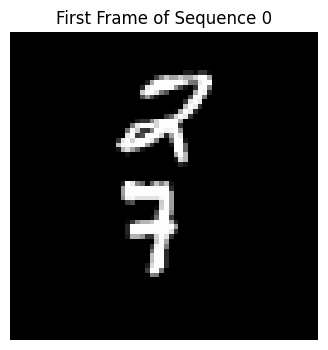

In [14]:
# Extract the 1st sequence: shape is (20, 1, 64, 64)
video_sequence = data[0]

# Extract the 1st frame: shape is (1, 64, 64)
first_frame = video_sequence[0]

# Plot the frame using Matplotlib
plt.figure(figsize=(4, 4))
plt.imshow(first_frame.squeeze(), cmap='gray')
plt.title("First Frame of Sequence 0")
plt.axis('off')
plt.show()

## Checks for transformations

In [15]:
## Checking if transformations are right or if i messed up
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64)
p[7,0,10,20] = 1

In [16]:
# check (a): max|M (M (x)) − x|
x_mm = mirror(x, 2)
torch.abs(x_mm - x).max()

tensor(0.)

In [17]:
# check (b):max|R4 (x) − x|
x_r4 = rotate(x, 4)
torch.abs(x_r4 - x).max()

tensor(0.)

In [18]:
#check (c): max|M RM (x) − R−1 (x)|
x_mrm = mirror(rotate(mirror(x), 1))
x_r_inv = rotate(x, -1)
torch.abs(x_mrm - x_r_inv).max()

tensor(0.)

In [19]:
#check(d):bright pixel of M (p) (frame, row, column)
m_p = mirror(p)

# Find the value and the flat index of the maximum element
max_val = torch.max(m_p)
max_idx = torch.argmax(m_p)

# Unravel the flat index into multi-dimensional coordinates (frame, channel, row, col)
# m_p shape is [20, 1, 64, 64]
shape = m_p.shape
coords = np.unravel_index(max_idx.item(), shape)

frame, channel, row, col = coords
print(f"Maximum pixel value: {max_val.item()}")
print(f"Coordinates - ({frame}, {row}, {col})")


Maximum pixel value: 1.0
Coordinates - (7, 10, 43)


In [20]:
#check (e): bright pixel of R(p) (frame, row, column)
r_p = rotate(p, 1)

# Find the value and the flat index of the maximum element
max_val = torch.max(r_p)
max_idx = torch.argmax(r_p)

# Unravel the flat index into multi-dimensional coordinates (frame, channel, row, col)
# r_p shape is [20, 1, 64, 64]
shape = r_p.shape
coords = np.unravel_index(max_idx.item(), shape)

frame, channel, row, col = coords
print(f"Maximum pixel value: {max_val.item()}")
print(f"Coordinates - ({frame}, {row}, {col})")

Maximum pixel value: 1.0
Coordinates - (7, 43, 10)


In [21]:
LOOKBACK = 5
HORIZON = 5

In [22]:
# 1. Grab a raw 20-frame sequence (bypassing dataset transform for demonstration)
raw_sequence = data.data[0] # shape: [20, 1, 64, 64]
print(f"Raw sequence shape: {raw_sequence.shape} (20 frames)")

# 2. Apply a speedup (e.g. stride = 2) to get 10 frames
stride_vals = [1, 2, 3]

for stride_val in stride_vals:
  print(f"\n----------STRIDE: {stride_val}------------")
  transformed_seq = raw_sequence[::stride_val]

  lookback_frames = transformed_seq[:LOOKBACK]
  target_frames = transformed_seq[LOOKBACK:LOOKBACK + HORIZON]

  print(f"Lookback Frames: {len(lookback_frames)}")
  print(f"Iindices from original raw 20 frames: {[(i * stride_val + 1) for i in range(LOOKBACK)]}")

  print(f"\nTarget / Horizon Frames: {len(target_frames)}")
  print(f"Iindices from original raw 20 frames: {[(i * stride_val + 1) for i in range(LOOKBACK, LOOKBACK + HORIZON)]}")

Raw sequence shape: torch.Size([20, 1, 64, 64]) (20 frames)

----------STRIDE: 1------------
Lookback Frames: 5
Iindices from original raw 20 frames: [1, 2, 3, 4, 5]

Target / Horizon Frames: 5
Iindices from original raw 20 frames: [6, 7, 8, 9, 10]

----------STRIDE: 2------------
Lookback Frames: 5
Iindices from original raw 20 frames: [1, 3, 5, 7, 9]

Target / Horizon Frames: 5
Iindices from original raw 20 frames: [11, 13, 15, 17, 19]

----------STRIDE: 3------------
Lookback Frames: 5
Iindices from original raw 20 frames: [1, 4, 7, 10, 13]

Target / Horizon Frames: 2
Iindices from original raw 20 frames: [16, 19, 22, 25, 28]


## Is training data symmetric? no clue

In [23]:
dof_vids = train_dataset[:50]
dof_vids.data.shape

torch.Size([50, 20, 1, 64, 64])

In [24]:
dof_vids_scaled = [sample * 255.0 for sample in dof_vids] #unit8 scale

In [25]:
import cv2
import numpy as np

# List to store the calculated optical flows
# Each flow element will have a shape of (H, W, 2) representing (u, v) flow fields
all_flows = []

for video_idx, video_tensor in enumerate(dof_vids_scaled):
    # video_tensor has shape [20, 1, 64, 64] or [20, 64, 64]
    # Ensure we convert it to a numpy array of uint8
    video_np = video_tensor.squeeze().cpu().numpy().astype(np.uint8)

    video_flows = []
    for s in range(19):
        prev_frame = video_np[s]
        next_frame = video_np[s + 1]

        # Compute dense optical flow using Farneback's method with the specified parameters
        flow = cv2.calcOpticalFlowFarneback(
            prev=prev_frame,
            next=next_frame,
            flow=None,
            pyr_scale=0.5,
            levels=3,
            winsize=15,
            iterations=3,
            poly_n=5,
            poly_sigma=1.2,
            flags=0
        )
        video_flows.append(flow)
    all_flows.append(video_flows)

# Convert to numpy array for easier downstream analysis
# Shape should be (50, 19, 64, 64, 2)
all_flows_np = np.array(all_flows)
print("Computed flow array shape:", all_flows_np.shape)
print("Total frame pairs analyzed:", all_flows_np.shape[0] * all_flows_np.shape[1])

Computed flow array shape: (50, 19, 64, 64, 2)
Total frame pairs analyzed: 950


In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Accumulate valid flows
filtered_dx_list = []
filtered_dy_list = []

# Iterate through each of the 50 videos
for video_idx in range(len(dof_vids_scaled)):
    video_np = dof_vids_scaled[video_idx].squeeze().cpu().numpy().astype(np.uint8)

    for s in range(19):
        prev_frame = video_np[s]
        next_frame = video_np[s + 1]
        flow_frame = all_flows_np[video_idx, s]  # shape (64, 64, 2)

        dx_frame = flow_frame[..., 0]
        dy_frame = flow_frame[..., 1]
        magnitude = np.sqrt(dx_frame**2 + dy_frame**2)

        # Create joint mask: intensity > 51 in both frames AND flow magnitude > 0.5
        cond = (prev_frame > 51) & (next_frame > 51) & (magnitude > 0.5)

        filtered_dx_list.extend(dx_frame[cond])
        filtered_dy_list.extend(dy_frame[cond])



### (a)histogram of flow direction

In [27]:
num_pixels_kept = len(filtered_dx_list)
print(f"Number of raw pixels: {50*20*64*64}")
print(f"Number of pixels kept: {num_pixels_kept}")

Number of raw pixels: 4096000
Number of pixels kept: 101434


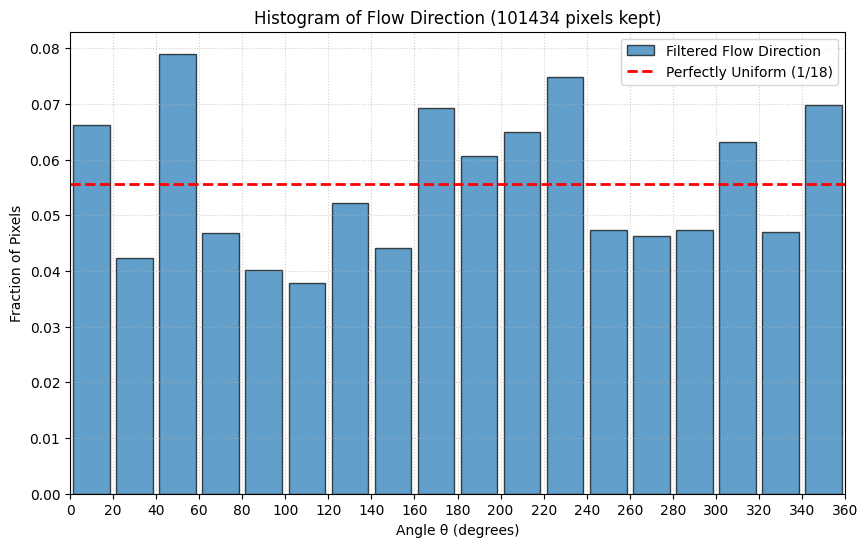

In [28]:
# Convert to numpy arrays
filtered_dx = np.array(filtered_dx_list)
filtered_dy = np.array(filtered_dy_list)

# Calculate theta = atan2(-dy, dx)
theta_rad = np.arctan2(-filtered_dy, filtered_dx)
theta_deg = np.degrees(theta_rad) % 360.0

# Plot histogram
plt.figure(figsize=(10, 6))
bins = np.linspace(0, 360, 19)
weights = np.ones_like(theta_deg) / len(theta_deg)

plt.hist(theta_deg, bins=bins, weights=weights, edgecolor='black', alpha=0.7, rwidth=0.85, label='Filtered Flow Direction')
plt.axhline(y=1/18, color='r', linestyle='--', linewidth=2, label='Perfectly Uniform (1/18)')

plt.title(f'Histogram of Flow Direction ({num_pixels_kept} pixels kept)')
plt.xlabel('Angle θ (degrees)')
plt.ylabel('Fraction of Pixels')
plt.xticks(np.arange(0, 361, 20))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.xlim(0, 360)
plt.show()

### (b)histogram of flow speed

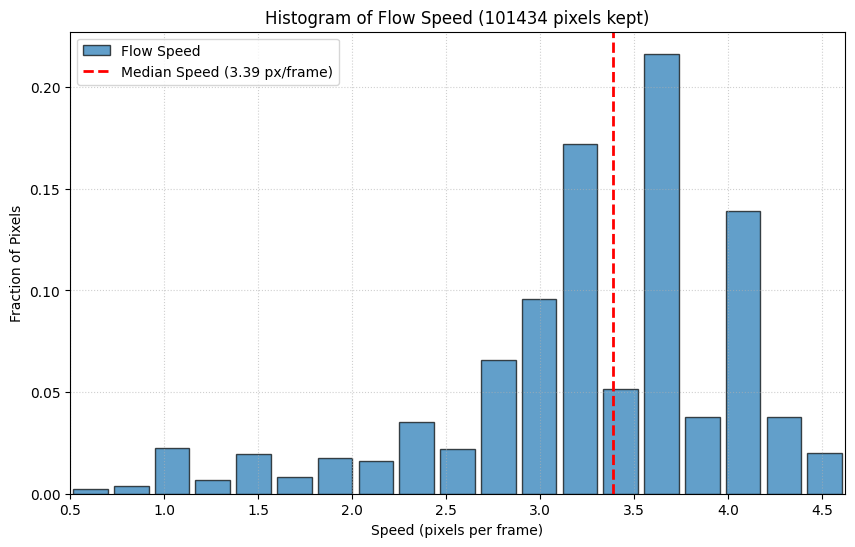

In [29]:
# Calculate speed = sqrt(dx**2 + dy**2)
speed = np.sqrt(filtered_dx**2 + filtered_dy**2)

# Plot histogram
plt.figure(figsize=(10, 6))

# Dynamically set bins based on the maximum speed observed
max_speed = np.percentile(speed, 99)  # focus on 99% of data for a cleaner plot
bins = np.linspace(0.5, max_speed, 20)
weights = np.ones_like(speed) / len(speed)
median_speed = np.median(speed)

plt.hist(speed, bins=bins, weights=weights, edgecolor='black', alpha=0.7, rwidth=0.85, label='Flow Speed')

# Draw a vertical line at the median speed
plt.axvline(x=median_speed, color='r', linestyle='--', linewidth=2, label=f'Median Speed ({median_speed:.2f} px/frame)')

plt.title(f'Histogram of Flow Speed ({num_pixels_kept} pixels kept)')
plt.xlabel('Speed (pixels per frame)')
plt.ylabel('Fraction of Pixels')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.xlim(0.5, max_speed)
plt.show()

#### Q2.1: Based on Figure 1(a), would mirrored and rotated trajectories already be familiar to a modeltrained on this data? (Hint: how would the direction histogram change if every trainingvideo were mirrored? If every video were rotated by 90◦ ?) From Figure 1(b), what is atypical speed, and what do 2× and 3× correspond to in pixels per frame? Optical flowis unreliable where digits overlap; could that bias your histograms enough to change youranswer?


**Answer:**
If all training videos were mirrored then the histogram would flip horizontally and peaks will be chnaged. Similarly, if training data was rotated by 90 degrees then movement angles of the moving digits would change. e.g. if a digit was moving right and was flipped by 90 degrees, it would start moving down now which would completely change the angle distribution present in 1(a). So for these new distributions, model would be unfamiliar. If original distribution was uniform, then model would have been fine because rotation and mirroring would keep distribution same.

From fig 1(b), typical speed is 3.26 px/frame. With 2x or 3x, the speed would increase because number of frames in a sample would reduce and the change in position of pixels in each frame would be a lot.




In [30]:
import cv2
import torch
import matplotlib.pyplot as plt

#created through gemini
def find_overlapping_frames_in_sequence(video_tensor, threshold=51):
    """
    Analyzes a 20-frame video sequence to find indices of frames where digits overlap.
    We threshold the frame and count the number of connected components (excluding background).
    """
    # video_tensor shape: [20, 1, 64, 64] or [20, 64, 64]
    video_np = video_tensor.squeeze().cpu().numpy()
    # Convert back to uint8 scale if normalized
    if video_np.max() <= 1.0:
        video_np = (video_np * 255.0).astype(np.uint8)
    else:
        video_np = video_np.astype(np.uint8)

    overlap_indices = []
    for idx, frame in enumerate(video_np):
        # Binary threshold
        _, thresh = cv2.threshold(frame, threshold, 255, cv2.THRESH_BINARY)
        # Find connected components
        num_labels, labels = cv2.connectedComponents(thresh)
        # num_labels includes background as label 0.
        # If num_labels - 1 is 1, it means the two digits have merged into a single connected component.
        num_digits = num_labels - 1
        if num_digits == 1:
            overlap_indices.append(idx)

    return overlap_indices

# Let's search across our subset of 50 videos to find some sequences that have overlapping frames
overlap_results = {}
for i in range(50):
    video_seq = train_dataset[i]
    overlapping_frames = find_overlapping_frames_in_sequence(video_seq)
    if len(overlapping_frames) > 0:
        overlap_results[i] = overlapping_frames

print(f"Found {len(overlap_results)} sequences with overlapping frames out of 50!")
if len(overlap_results) > 0:
    first_overlap_video = list(overlap_results.keys())[0]
    print(f"Sequence {first_overlap_video} has overlaps at frames: {overlap_results[first_overlap_video]}")

Found 47 sequences with overlapping frames out of 50!
Sequence 0 has overlaps at frames: [2, 3, 10, 11, 12, 13]


In [31]:
overlap_results

{0: [2, 3, 10, 11, 12, 13],
 1: [15, 16, 17, 19],
 2: [4, 5, 6, 17, 18, 19],
 3: [0, 1, 2, 3, 4, 5, 15, 16, 17, 18, 19],
 4: [2, 3, 4, 5, 6, 15, 16, 17, 18],
 5: [2, 3, 4, 5, 14, 15, 16, 17, 18],
 6: [0, 1, 2, 3, 4, 5, 6, 7, 8],
 7: [14, 15, 16, 17, 18, 19],
 8: [0, 1, 2, 12, 13, 14, 15, 16, 17, 18, 19],
 9: [2, 3, 4, 5, 10, 11, 12],
 10: [0, 9, 10, 11],
 11: [1, 2, 3, 12, 13, 14, 15, 16],
 12: [0, 1, 7, 8, 9],
 13: [0, 1, 2, 3, 4, 6, 7, 8, 9, 10, 11],
 14: [14, 15, 16, 17, 18, 19],
 15: [2, 3, 4, 18, 19],
 16: [0, 1, 2, 3, 4],
 17: [0, 1, 5, 6, 7, 8],
 18: [1, 2, 7, 11, 16, 17, 18, 19],
 19: [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 20: [4, 5, 6, 7, 8, 9],
 21: [4, 5, 6, 16, 17, 18, 19],
 22: [5, 6, 7, 8, 9, 17, 18, 19],
 23: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 24: [0, 1, 2],
 25: [4, 5, 6, 7, 17, 18, 19],
 26: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 27: [0, 7, 18, 19],
 29: [4, 5, 6, 7, 8, 9, 10, 11],
 30: [7, 8, 9, 18, 19],


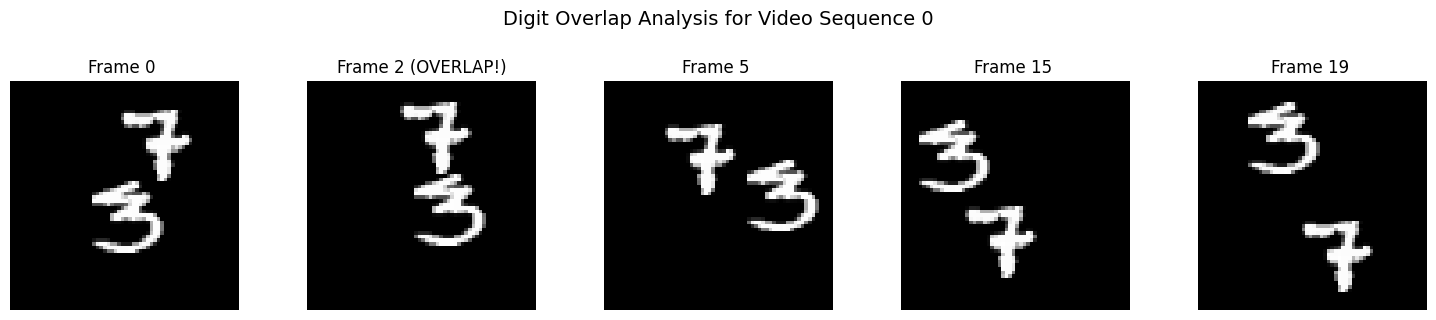

In [32]:
# Let's visualize one sequence with its overlapping frames
if len(overlap_results) > 0:
    vid_idx = list(overlap_results.keys())[0]
    overlap_frames = overlap_results[vid_idx]

    video_tensor = train_dataset[vid_idx]
    video_np = video_tensor.squeeze().cpu().numpy()

    # Select a few frames to show: some normal ones and the overlapping ones
    fig, axes = plt.subplots(1, 5, figsize=(15, 3))
    # We'll plot frames 0, 5, 10, 15, and the first detected overlapping frame
    frames_to_show = [0, 5, overlap_frames[0], 15, 19]
    # Ensure unique and sorted indices
    frames_to_show = sorted(list(set(frames_to_show)))

    for ax, f_idx in zip(axes, frames_to_show):
        ax.imshow(video_np[f_idx], cmap='gray')
        is_overlap = "(OVERLAP!)" if f_idx in overlap_frames else ""
        ax.set_title(f"Frame {f_idx} {is_overlap}")
        ax.axis('off')

    plt.suptitle(f"Digit Overlap Analysis for Video Sequence {vid_idx}", fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()

Since there are QUITE A LOT (48/50) of overlapping sequences so yes it would change our histographs in this case.

#### **Q2.2:** For each transformation, does it change the motion statistics, the digit appearance, or both? Why does this make the three of them useful as a controlled experiment?

**Answer:** For both mirroring and rotationm, the digit appearance would change as well as motion stats.For speed changes, only motion stats change, not the appearance. Since the behavior of moving digits is a bit different after these transformations, they could prove useful to test the generalizability of our model. If model fails on transformed images, we have a guide as to where the model experiences trouble.

## Baseline. finally!

In [33]:
import torch
import torch.nn as nn
import torch.nn.functional as F

#conv layer
class ConvLSTM(nn.Module):
    def __init__(self, in_channels, hidden=64):
        super().__init__()
        self.hidden = hidden
        # one conv makes all 4 gates (i,o,f,g) at once
        self.conv = nn.Conv2d(in_channels + hidden, 4 * hidden, 3, padding=1, bias=True, stride=1)

    def forward(self, x, h, c):
        out = self.conv(torch.cat([x, h], dim=1))
        H = self.hidden
        i = torch.sigmoid(out[:, 0*H:1*H])
        f = torch.sigmoid(out[:, 1*H:2*H])
        o = torch.sigmoid(out[:, 2*H:3*H])
        g = torch.tanh(out[:, 3*H:4*H])

        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c



In [34]:
# baseline model A
class BaselineModelA(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = ConvLSTM(16, 64)
        self.layer2 = ConvLSTM(64, 64)
        self.to_frame = nn.Conv2d(64, 16, 1)

    def step(self, frame, h1, c1, h2, c2):
        x = F.pixel_unshuffle(frame, 4)
        h1, c1 = self.layer1(x, h1, c1)
        h2, c2 = self.layer2(h1, h2, c2)
        pred = torch.sigmoid(F.pixel_shuffle(self.to_frame(h2), 4))
        return pred, h1, c1, h2, c2

    def forward(self, video): # (B, T, 1, 64,64)
        B, T = video.shape[:2]

        zeros = lambda: torch.zeros(B, 64, 16, 16, device=video.device)
        h1, c1, h2, c2 = zeros(), zeros(), zeros(), zeros()

        preds = []
        for t in range(1, 10):
            if t<=5:
              u = video[:, t-1]
            else:
              u = pred
            pred, h1, c1, h2, c2 = self.step(u, h1, c1, h2, c2)
            preds.append(pred)

        return torch.stack(preds[4:], dim=1) # after 4th frame (5-9)

In [35]:
#checking params
a = BaselineModelA()
num_params = sum(p.numel() for p in a.parameters() if p.requires_grad)
print("params:", num_params)

params: 480784


In [36]:
def get_window(video, t, k=1):
    """video: (20,1,64,64) float in [0,1]; t is 1-based frame number."""
    in_idx = [t - 1 + j * k for j in range(5)]            # 0-based indices of inputs
    tgt_frames = [t + (5 + j) * k for j in range(5)]      # 1-based target frame numbers
    avail = [f for f in tgt_frames if f <= 20]            # only targets that exist i.e until 20 frames
    n = len(avail)

    x_in = video[in_idx]                                  # (5,1,64,64)
    y = torch.zeros(5, 1, 64, 64)
    y[:n] = video[[f - 1 for f in avail]]
    mask = torch.zeros(5)
    mask[:n] = 1.0
    return x_in, y, mask


class TrainDataset(torch.utils.data.Dataset):
    """Models A/B: normal speed, t drawn from 1..11."""
    def __init__(self, videos, window_rng, aug_rng=None):
        self.videos, self.rng, self.aug_rng = videos, window_rng, aug_rng

    def __len__(self):
        return len(self.videos)                           # 8000

    def __getitem__(self, i):
        t = int(self.rng.integers(1, 12))                 # 1..11 inclusive
        return get_window(self.videos[i], t, k=1)


class EvalDataset(torch.utils.data.Dataset):
    """Validation / test: fixed window t=1, 1x."""
    def __init__(self, videos):
        self.videos = videos

    def __len__(self):
        return len(self.videos)

    def __getitem__(self, i):
        return get_window(self.videos[i], t=1, k=1)

In [37]:
import random, numpy as np, torch

def make_run(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                       # model initialisation
    torch.cuda.manual_seed_all(seed)
    shuffle_gen = torch.Generator().manual_seed(seed)       # shuffling
    window_rng  = np.random.default_rng(seed)               # window sampling
    aug_rng     = np.random.default_rng(seed + 10_000)      # augmentation, if any
    return shuffle_gen, window_rng, aug_rng

In [38]:
#trainign loop
import time

def train(model, seed, train_videos, epochs=30):
    shuffle_gen, window_rng, aug_rng = make_run(seed)
    model = model.to(device)                       # seeded init
    opt = optimizer(model.parameters())

    ds = TrainDataset(train_videos, window_rng, aug_rng)   # samples a NEW window per access
    loader = torch.utils.data.DataLoader(
        ds, batch_size=BATCH_SIZE, shuffle=True, generator=shuffle_gen, num_workers=0)

    epoch_times, losses = [], []
    for ep in range(epochs):
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()

        model.train()
        total, n = 0.0, 0
        for x_in, y, mask in loader:
            x_in, y, mask = x_in.to(device), y.to(device), mask.to(device)
            loss = mse_loss(model(x_in), y, mask)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * x_in.size(0); n += x_in.size(0)

        if device == "cuda": torch.cuda.synchronize()
        epoch_times.append(time.perf_counter() - t0)
        losses.append(total / n)
        print(f"seed {seed} epoch {ep+1}/{epochs} loss {losses[-1]:.5f}")

    torch.save(model.state_dict(), f"model_a_seed{seed}.pt")    # final-epoch weights
    return model, sum(epoch_times) / len(epoch_times), losses

In [39]:
#dumb/naive models
def predict_blank(x_in):
    # x_in: (B,5,1,64,64) -> all-zero frames
    return torch.zeros(x_in.size(0), 5, 1, 64, 64, device=x_in.device)

def predict_copy_last(x_in):
    # repeat the last input frame (frame 5) five times
    return x_in[:, -1:].expand(-1, 5, -1, -1, -1)

In [40]:
@torch.no_grad()
def mse_by_horizon(predict, loader, device):
    """Returns a tensor of 5 values: MSE_1 ... MSE_5, averaged over videos."""
    total = torch.zeros(5, device=device)
    count = torch.zeros(5, device=device)
    for x_in, y, mask in loader:
        x_in, y, mask = x_in.to(device), y.to(device), mask.to(device)
        pred = predict(x_in)                              # (B,5,1,64,64)
        se = ((pred - y) ** 2).mean(dim=(2, 3, 4))        # (B,5): MSE_h per video
        total += (se * mask).sum(0)
        count += mask.sum(0)
    return total / count

def summarise(mse_h):
    return dict(mse_h=mse_h.tolist(),
                E5=mse_h.mean().item(),          # (1/5) * sum_{h=1..5} MSE_h
                E2=mse_h[:2].mean().item())      # (1/2) * sum_{h=1..2} MSE_h

In [41]:
#inference
@torch.no_grad()
def timed_inference(model, loader):
    model.eval(); total = 0.0
    for x_in, y, mask in loader:
        x_in = x_in.to(device)                           # transfer is outside the timer
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        model(x_in)
        if device == "cuda": torch.cuda.synchronize()
        total += time.perf_counter() - t0
    return total

def sig3(x): return f"{x:.2e}" if abs(x) < 1e-3 else f"{x:.3g}"
def cell(vals):
    m = sum(vals) / len(vals)
    return f"{sig3(m)} ({', '.join(sig3(v) for v in vals)})"

### Baseline A training and Evaluation

In [42]:
test_loader = DataLoader(EvalDataset(test_dataset), batch_size=32, shuffle=False)

res = {}
for seed in (0, 1):
    print(f"-------------Seed: {seed}--------------")
    model, t_epoch, losses = train(a, seed, train_dataset)
    model.eval()
    res[seed] = dict(**summarise(mse_by_horizon(model, test_loader, device)),
                     t_train=t_epoch, t_infer=timed_inference(model, test_loader))

ref = {"Blank": summarise(mse_by_horizon(predict_blank, test_loader, device)),
       "Copy-last": summarise(mse_by_horizon(predict_copy_last, test_loader, device))}

-------------Seed: 0--------------
seed 0 epoch 1/30 loss 0.04657
seed 0 epoch 2/30 loss 0.04010
seed 0 epoch 3/30 loss 0.04007
seed 0 epoch 4/30 loss 0.04008
seed 0 epoch 5/30 loss 0.03997
seed 0 epoch 6/30 loss 0.03941
seed 0 epoch 7/30 loss 0.03836
seed 0 epoch 8/30 loss 0.03500
seed 0 epoch 9/30 loss 0.03230
seed 0 epoch 10/30 loss 0.03105
seed 0 epoch 11/30 loss 0.03022
seed 0 epoch 12/30 loss 0.02978
seed 0 epoch 13/30 loss 0.02937
seed 0 epoch 14/30 loss 0.02908
seed 0 epoch 15/30 loss 0.02861
seed 0 epoch 16/30 loss 0.02843
seed 0 epoch 17/30 loss 0.02789
seed 0 epoch 18/30 loss 0.02768
seed 0 epoch 19/30 loss 0.02723
seed 0 epoch 20/30 loss 0.02693
seed 0 epoch 21/30 loss 0.02644
seed 0 epoch 22/30 loss 0.02611
seed 0 epoch 23/30 loss 0.02574
seed 0 epoch 24/30 loss 0.02541
seed 0 epoch 25/30 loss 0.02499
seed 0 epoch 26/30 loss 0.02470
seed 0 epoch 27/30 loss 0.02436
seed 0 epoch 28/30 loss 0.02408
seed 0 epoch 29/30 loss 0.02382
seed 0 epoch 30/30 loss 0.02358
-------------S

In [43]:
import pandas as pd
df = pd.DataFrame(
    [[f"MSE{h+1}", cell([res[s]["mse_h"][h] for s in (0, 1)]),
      sig3(ref["Blank"]["mse_h"][h]), sig3(ref["Copy-last"]["mse_h"][h])] for h in range(5)]
    + [["E5", cell([res[s]["E5"] for s in (0, 1)]),
        sig3(ref["Blank"]["E5"]), sig3(ref["Copy-last"]["E5"])],
       ["Params", num_params, 0, 0]],
    columns=["Metric", "Model A total (s1, s2)", "Blank", "Copy-last"])
print(df.to_string(index=False))  

Metric  Model A total (s1, s2)  Blank Copy-last
  MSE1 0.0165 (0.0193, 0.0136) 0.0428    0.0489
  MSE2 0.0194 (0.0221, 0.0168) 0.0428     0.061
  MSE3 0.0218 (0.0242, 0.0195) 0.0428    0.0673
  MSE4 0.0237 (0.0257, 0.0216) 0.0428    0.0711
  MSE5 0.0254 (0.0271, 0.0237) 0.0428    0.0736
    E5  0.0214 (0.0237, 0.019) 0.0428    0.0644
Params                  480784      0         0


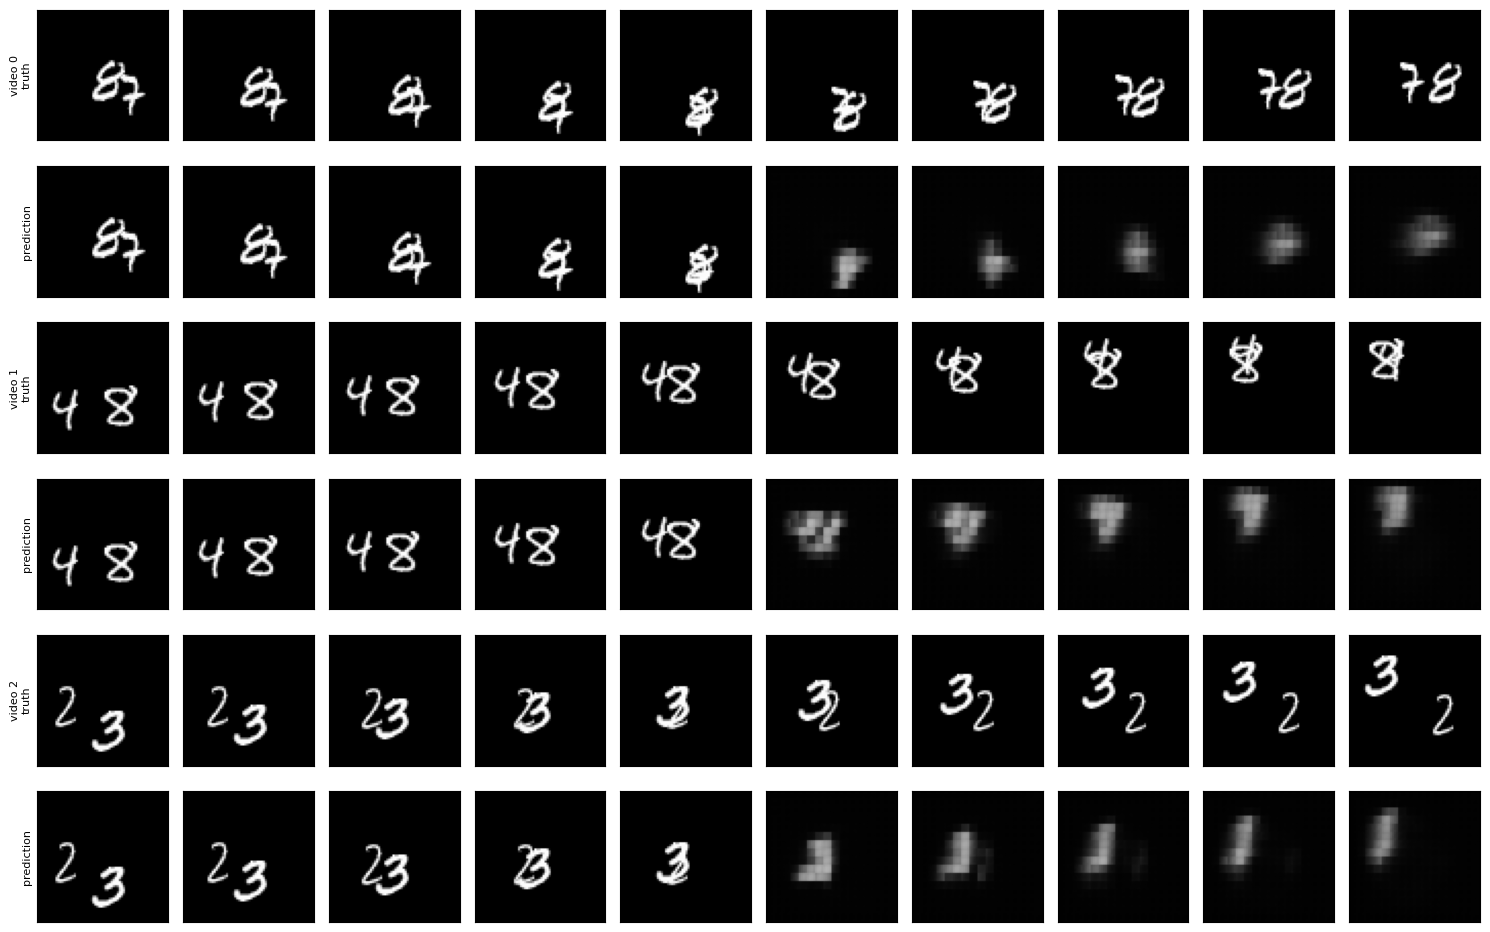

In [44]:
@torch.no_grad()
def show_figure2(model, test_set, video_ids, path="figure2.png"):
    model.eval()
    fig, axes = plt.subplots(2 * len(video_ids), 10, figsize=(15, 3.2 * len(video_ids)))
    for r, vid in enumerate(video_ids):
        x_in, y, mask = test_set[vid]
        y_hat = model(x_in[None].to(device))[0].cpu()
        for c in range(10):
            top = x_in[c] if c < 5 else y[c - 5]
            bot = x_in[c] if c < 5 else y_hat[c - 5]
            axes[2*r, c].imshow(top[0], cmap="gray", vmin=0, vmax=1)
            axes[2*r+1, c].imshow(bot[0], cmap="gray", vmin=0, vmax=1)
            for ax in (axes[2*r, c], axes[2*r+1, c]): ax.set_xticks([]); ax.set_yticks([])
        axes[2*r, 0].set_ylabel(f"video {vid}\ntruth", fontsize=8)
        axes[2*r+1, 0].set_ylabel("prediction", fontsize=8)
    plt.tight_layout(); plt.savefig(path, dpi=150)

m0 = a.to(device); m0.load_state_dict(torch.load("model_a_seed0.pt", map_location=device))
show_figure2(m0, EvalDataset(test_dataset), video_ids=[0, 1, 2])   

#### **Q2.3:** Estimate model A’s reach in original pixels per time step, using the conventions above. Walk through your reasoning from the patch size, kernel sizes, number of layers and the recurrence.There is no formula to look up for this.

**Answer:**
starting out with folded grid where our 1x64x64 grid patch was converted into 16x16x16. So now one pixel corresponds to 16 original pixels that have been shifted to be channels. In each direction, the reach/distance in this case would be 4 covered now by 1 pixel in the folded grid. So after on conv layer, the distance observed by model is 1 in each direction so reach becomes:

    reach1 = 4x1 = 4px
    
Then after the next conv layer, the grid dimensions remain same because of padding and 1 stride. But the area observed by the model increases 1 step further in each direction and becomes 2. So the reach/distance now becomes:

    reach2 = 4x2 = 8px

Afterwards, we ahave 1x1 convolutions which dont move info so we can ignore those. So Model A's reach becomes 8 pixels (in each direction).
